# Chinook Sales Analysis

Exploratory analysis of the Chinook sample database (a digital music store) using
SQL and Python. Each business question is answered with a query stored in `Sql/`,
loaded here with pandas and visualized with matplotlib.

**Questions:**
1. How does revenue evolve year over year?
2. Which countries generate the most revenue?
3. How much do low, medium and high-value invoices weigh?
4. Where are the customers?

In [14]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("Data/Chinook_Sqlite.sqlite")
SQL_DIR = Path("Sql")

conn = sqlite3.connect(DB_PATH)

print("Database found:", DB_PATH.exists())

Database found: True


In [15]:
def run_sql_file(filename):
    """Read a .sql file from the Sql folder and return the result as a DataFrame."""
    query = (SQL_DIR / filename).read_text(encoding="utf-8")
    return pd.read_sql_query(query, conn)

In [17]:
# Load each SQL file into a DataFrame
df_year = run_sql_file("01_revenue_by_year.sql")
df_country = run_sql_file("02_revenue_by_country.sql")
df_category = run_sql_file("03_invoices_by_category.sql")
df_customers = run_sql_file("04_customers_by_country.sql")

df_year

,year,num_invoices,revenue,avg_invoice
0,2021,83,449.46,5.42
1,2022,83,481.45,5.80
2,2023,83,469.58,5.66
3,2024,83,477.53,5.75
4,2025,80,450.58,5.63


In [18]:
# Sanity checks: totals should match across queries
print("Invoices (by year):      ", df_year["num_invoices"].sum())          # 412
print("Revenue (by year):       ", round(df_year["revenue"].sum(), 2))     # ~2328.60
print("Invoices (by country):   ", df_country["num_invoices"].sum())       # 412
print("Invoices (by category):  ", df_category["num_invoices"].sum())      # 412
print("Customers:               ", df_customers["num_customers"].sum())    # 59
print("Customers with company:  ", df_customers["with_company"].sum())     # 10

Invoices (by year):       412
Revenue (by year):        2328.6
Invoices (by country):    412
Invoices (by category):   412
Customers:                59
Customers with company:   10


In [21]:
# Category summary and date range covered by the data
print(df_category)

pd.read_sql_query(
    "SELECT MIN(InvoiceDate) AS first_date, MAX(InvoiceDate) AS last_date FROM Invoice;",
    conn
)

  category  num_invoices  revenue
0     high           122  1458.23
1   medium           120   588.18
2      low           170   282.19


,first_date,last_date
0,2021-01-01 00:00:00,2025-12-22 00:00:00


In [22]:
# Share of total revenue (%) by country and by invoice category
df_country["pct_revenue"] = (df_country["revenue"] / df_country["revenue"].sum() * 100).round(1)
df_category["pct_revenue"] = (df_category["revenue"] / df_category["revenue"].sum() * 100).round(1)

df_country.head(10)

,BillingCountry,num_invoices,revenue,avg_invoice,pct_revenue
0,USA,91,523.06,5.75,22.5
1,Canada,56,303.96,5.43,13.1
2,France,35,195.10,5.57,8.4
3,Brazil,35,190.10,5.43,8.2
4,Germany,28,156.48,5.59,6.7
5,United Kingdom,21,112.86,5.37,4.8
6,Czech Republic,14,90.24,6.45,3.9
7,Portugal,14,77.24,5.52,3.3
8,India,13,75.26,5.79,3.2
9,Chile,7,46.62,6.66,2.0


In [23]:
CHARTS_DIR = Path("Charts")
CHARTS_DIR.mkdir(exist_ok=True)

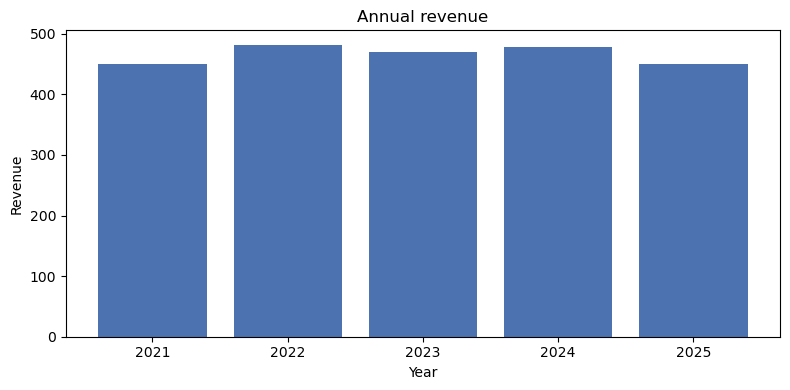

In [24]:
# Chart 1: annual revenue
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df_year["year"], df_year["revenue"], color="#4C72B0")
ax.set_title("Annual revenue")
ax.set_xlabel("Year")
ax.set_ylabel("Revenue")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_revenue_by_year.png", dpi=150)
plt.show()

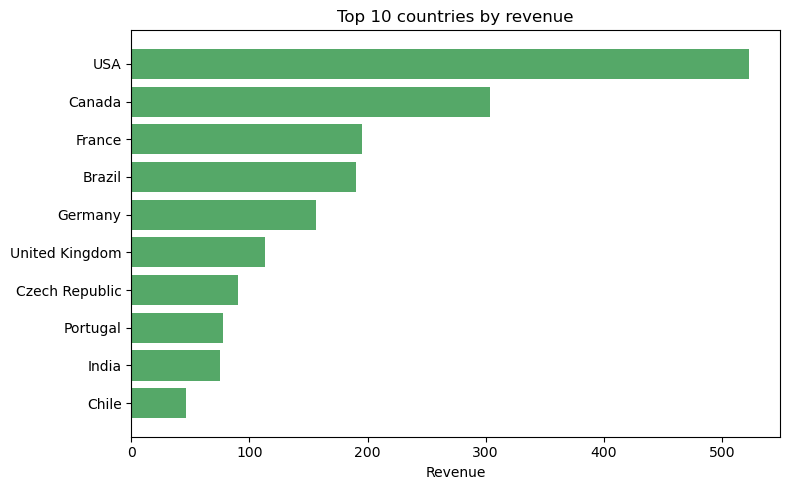

In [25]:
# Chart 2: top 10 countries by revenue
top_countries = df_country.head(10).sort_values("revenue")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_countries["BillingCountry"], top_countries["revenue"], color="#55A868")
ax.set_title("Top 10 countries by revenue")
ax.set_xlabel("Revenue")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_top_countries_revenue.png", dpi=150)
plt.show()

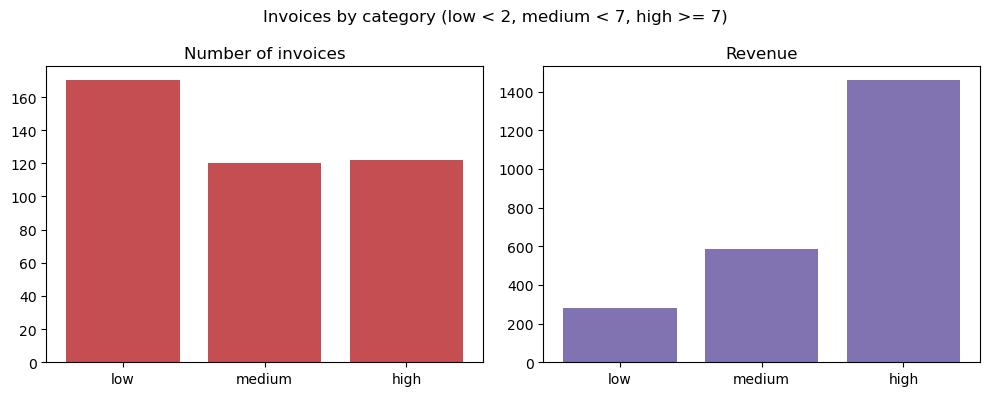

In [26]:
# Chart 3: invoices by category (count vs. revenue)
order = ["low", "medium", "high"]
df_cat = df_category.set_index("category").loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(df_cat["category"], df_cat["num_invoices"], color="#C44E52")
axes[0].set_title("Number of invoices")
axes[1].bar(df_cat["category"], df_cat["revenue"], color="#8172B2")
axes[1].set_title("Revenue")
fig.suptitle("Invoices by category (low < 2, medium < 7, high >= 7)")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "03_invoice_categories.png", dpi=150)
plt.show()

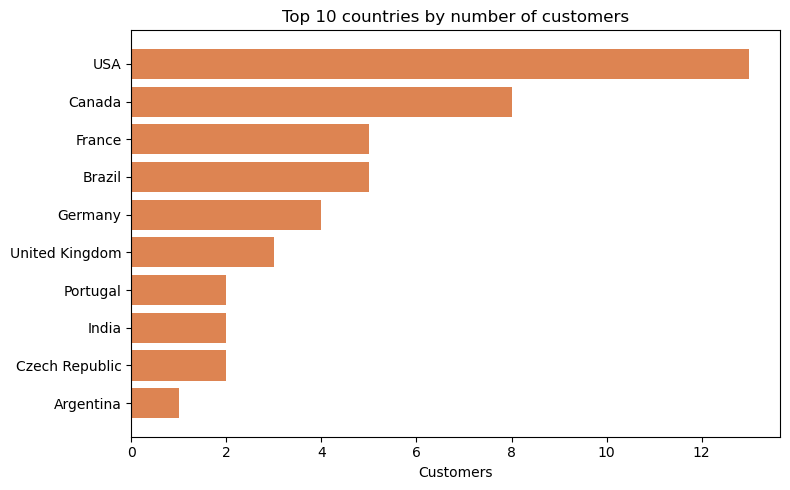

In [27]:
# Chart 4: top 10 countries by number of customers
top_customers = df_customers.head(10).sort_values("num_customers")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_customers["Country"], top_customers["num_customers"], color="#DD8452")
ax.set_title("Top 10 countries by number of customers")
ax.set_xlabel("Customers")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "04_customers_by_country.png", dpi=150)
plt.show()

In [28]:
# Check: invoices per customer by country (explains the revenue ranking)
df_comp = df_country.merge(df_customers, left_on="BillingCountry", right_on="Country")
df_comp["invoices_per_customer"] = (df_comp["num_invoices"] / df_comp["num_customers"]).round(1)

df_comp[["BillingCountry", "num_customers", "num_invoices", "invoices_per_customer"]].head(10)

,BillingCountry,num_customers,num_invoices,invoices_per_customer
0,USA,13,91,7.0
1,Canada,8,56,7.0
2,France,5,35,7.0
3,Brazil,5,35,7.0
4,Germany,4,28,7.0
5,United Kingdom,3,21,7.0
6,Czech Republic,2,14,7.0
7,Portugal,2,14,7.0
8,India,2,13,6.5
9,Chile,1,7,7.0
